# 芒果叶片病害分类 | MDCN


## 1. 导入依赖库与配置参数

In [1]:
import copy
import csv
import json
import random
import sys
from pathlib import Path

import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False
import numpy as np
import seaborn as sns
import torch
import torch.nn as nn
from PIL import Image, ImageFile
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.preprocessing import label_binarize
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms
from tqdm import tqdm

# 实验开关
FREEZE_BACKBONE = True    # True: 冻结主干，只训练分类头（论文 §3.4，收敛更慢）
USE_AUGMENTATION = False  # True: 训练集启用随机裁剪 / 翻转 / 颜色抖动

# 训练配置
SEED = 42
BATCH_SIZE = 5
NUM_EPOCHS = 100
LEARNING_RATE = 1e-5
WEIGHT_DECAY = 1e-4
DROPOUT_RATE = 0.2
PATIENCE = 10
IMG_SIZE = 224
NUM_WORKERS = 0
USE_PRETRAINED = True

# 70/20/10 划分下 train 2800 张的实测统计量
DATASET_MEAN = [0.6690, 0.6907, 0.6845]
DATASET_STD = [0.2018, 0.1920, 0.2639]

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = False
torch.backends.cudnn.benchmark = True

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == 'train':
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_DIR = PROJECT_ROOT / 'Mango Leaf Dataset'
MODEL_DIR = PROJECT_ROOT / 'models'
RUNS_DIR = PROJECT_ROOT / 'train' / 'runs'
MODEL_DIR.mkdir(parents=True, exist_ok=True)
RUNS_DIR.mkdir(parents=True, exist_ok=True)

RUN_DIR = RUNS_DIR  # 输出覆盖 train/runs 下的旧结果

MODEL_PREFIX = 'mango_mdcn'
CHECKPOINT_PATH = MODEL_DIR / f'{MODEL_PREFIX}_best_checkpoint.pth'
FINAL_MODEL_PATH = MODEL_DIR / f'{MODEL_PREFIX}_model.pth'
HISTORY_PATH = RUN_DIR / f'{MODEL_PREFIX}_history.csv'
METRICS_PATH = RUN_DIR / f'{MODEL_PREFIX}_metrics.json'
PREDICTIONS_PATH = RUN_DIR / f'{MODEL_PREFIX}_predictions.csv'

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'数据集目录未找到: {DATA_DIR}')

print(f'数据: {DATA_DIR}')
print(f'设备: {DEVICE} | PyTorch {torch.__version__} | Python {sys.version.split()[0]}')
print(f'配置: batch={BATCH_SIZE}, epochs={NUM_EPOCHS}, lr={LEARNING_RATE}, dropout={DROPOUT_RATE}')
print(f'模式: freeze_backbone={FREEZE_BACKBONE}, augmentation={USE_AUGMENTATION}')
print(f'输出: {RUN_DIR}')


数据: D:\WorkSpace2\plants-intelligent-system\Mango Leaf Dataset
设备: cuda | PyTorch 1.13.1 | Python 3.10.8
配置: batch=5, epochs=100, lr=1e-05, dropout=0.2
模式: freeze_backbone=True, augmentation=False
输出: D:\WorkSpace2\plants-intelligent-system\train\runs


## 2. 数据加载与预处理

In [2]:
ImageFile.LOAD_TRUNCATED_IMAGES = True

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(DATASET_MEAN, DATASET_STD),
])

if USE_AUGMENTATION:
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.ToTensor(),
        transforms.Normalize(DATASET_MEAN, DATASET_STD),
    ])
else:
    train_transform = eval_transform

split_dirs = {split: DATA_DIR / split for split in ('train', 'val', 'test')}
missing_splits = [split for split, path in split_dirs.items() if not path.is_dir()]
if missing_splits:
    raise FileNotFoundError(f'缺少数据集划分: {missing_splits}')

# 检查损坏图片
image_extensions = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
invalid_files = []
for split, split_dir in split_dirs.items():
    for image_path in split_dir.rglob('*'):
        if image_path.suffix.lower() in image_extensions:
            try:
                with Image.open(image_path) as img:
                    img.verify()
            except Exception as e:
                invalid_files.append(f'{split}: {image_path.name} ({e})')
if invalid_files:
    raise RuntimeError(f'发现损坏的图片文件:\n' + '\n'.join(invalid_files[:10]))

image_datasets = {
    split: datasets.ImageFolder(
        path,
        transform=(train_transform if split == 'train' else eval_transform),
    )
    for split, path in split_dirs.items()
}

class_names = image_datasets['train'].classes
class_to_idx = image_datasets['train'].class_to_idx
num_classes = len(class_names)

for split, dataset in image_datasets.items():
    if dataset.class_to_idx != class_to_idx:
        raise ValueError(f'{split} 集的类别映射与训练集不一致')
    if not dataset.samples:
        raise ValueError(f'{split} 集为空')

loaders = {
    split: DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=(split == 'train'),
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda'),
    )
    for split, dataset in image_datasets.items()
}

print('\n数据集统计:')
for split in ['train', 'val', 'test']:
    dataset = image_datasets[split]
    counts = np.bincount(dataset.targets, minlength=num_classes)
    print(f'{split:5s}: {len(dataset):4d} 张 | 各类: {counts.tolist()}')

print(f'\n类别映射: {class_to_idx}')
print(f'类别数量: {num_classes}')
print(f'训练集增强: {USE_AUGMENTATION}')



数据集统计:
train: 2800 张 | 各类: [350, 350, 350, 350, 350, 350, 350, 350]
val  :  800 张 | 各类: [100, 100, 100, 100, 100, 100, 100, 100]
test :  400 张 | 各类: [50, 50, 50, 50, 50, 50, 50, 50]

类别映射: {'Anthracnose': 0, 'Bacterial Canker': 1, 'Cutting Weevil': 2, 'Die Back': 3, 'Gall Midge': 4, 'Healthy': 5, 'Powdery Mildew': 6, 'Sooty Mould': 7}
类别数量: 8
训练集增强: False


## 3. 数据集可视化

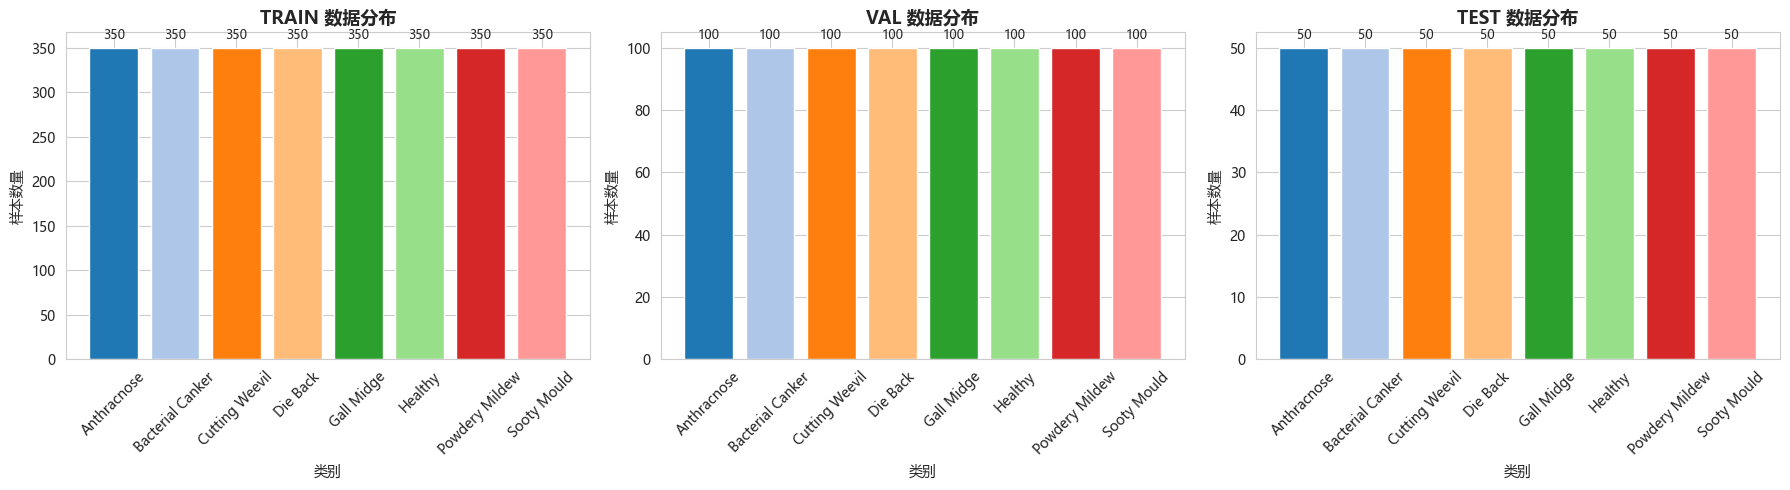

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
colors = plt.cm.tab20.colors[:num_classes]

for idx, split in enumerate(['train', 'val', 'test']):
    targets = image_datasets[split].targets
    class_counts = [targets.count(i) for i in range(num_classes)]
    axes[idx].bar(class_names, class_counts, color=colors)
    axes[idx].set_title(f'{split.upper()} 数据分布', fontsize=13, fontweight='bold')
    axes[idx].set_xlabel('类别')
    axes[idx].set_ylabel('样本数量')
    axes[idx].tick_params(axis='x', rotation=45)
    for i, count in enumerate(class_counts):
        axes[idx].text(i, count + max(class_counts) * 0.02, str(count), ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

### 3.2 样本展示

每类随机取 5 张训练图，用于快速判断数据难度（背景、拍摄条件、病斑是否明显）。


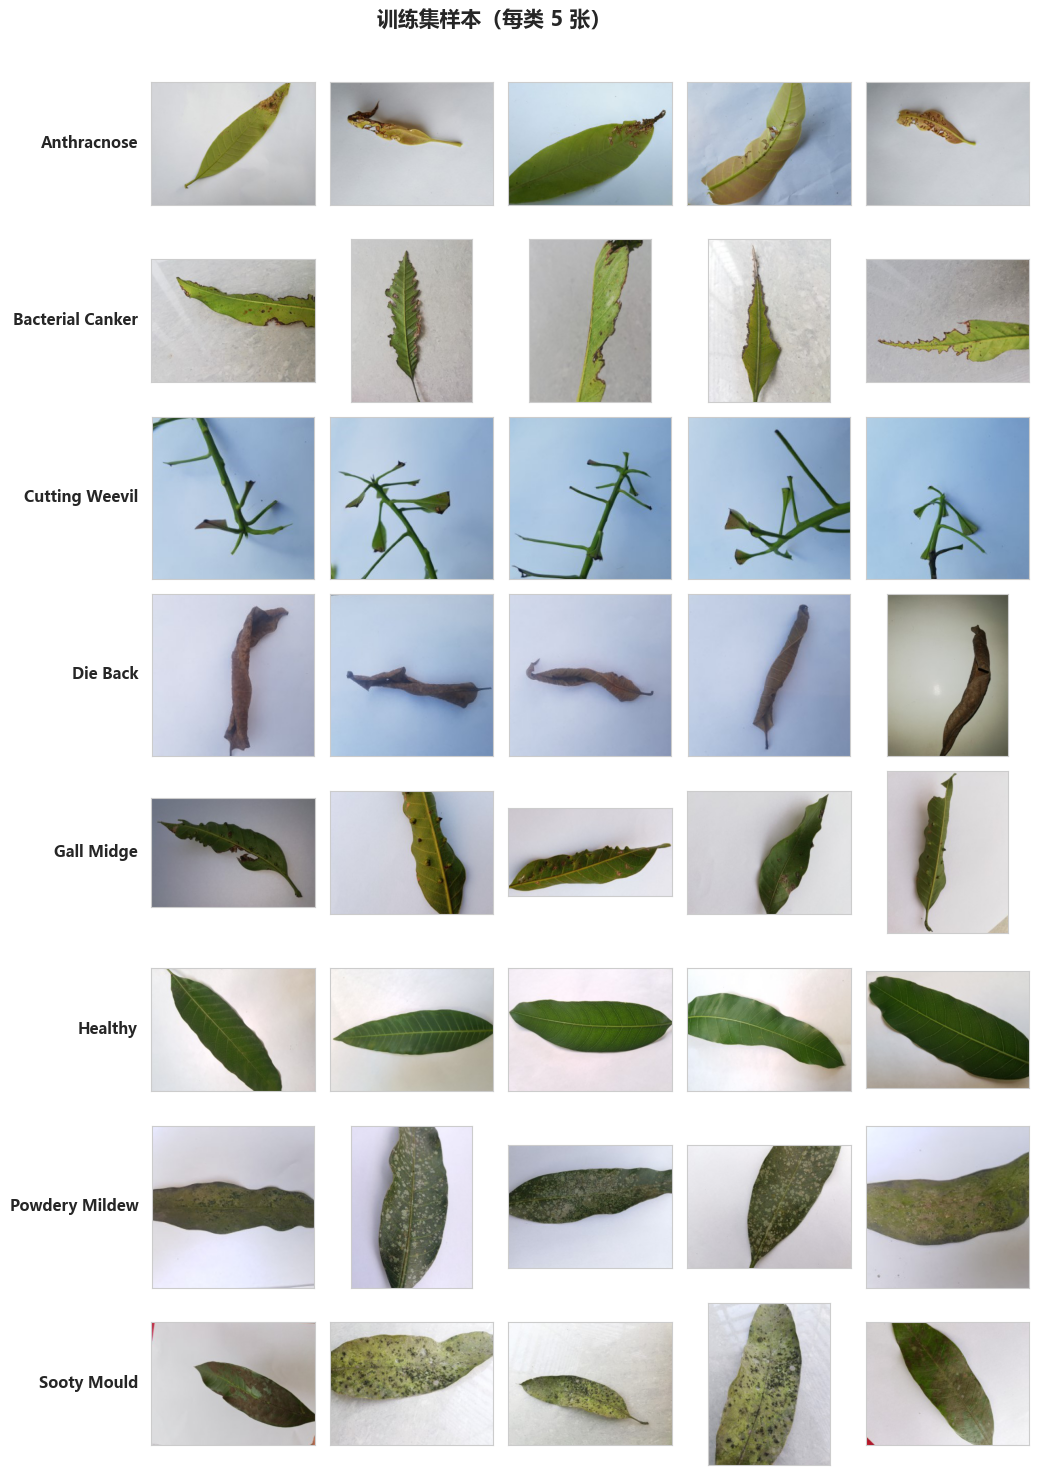

样本图已保存: D:\WorkSpace2\plants-intelligent-system\train\runs\dataset_samples_grid.png


In [4]:
n_show = 5
rng = np.random.default_rng(SEED)
samples_by_class = {
    c: [p for p, t in image_datasets['train'].samples if class_names[t] == c]
    for c in class_names
}

fig, axes = plt.subplots(num_classes, n_show, figsize=(11, 15))
for r, cls in enumerate(class_names):
    for k, path in enumerate(rng.choice(samples_by_class[cls], n_show, replace=False)):
        ax = axes[r, k]
        with Image.open(path) as im:
            ax.imshow(im.convert('RGB'))
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color('#cccccc')
    axes[r, 0].text(-0.08, 0.5, cls, transform=axes[r, 0].transAxes,
                    ha='right', va='center', fontsize=11, fontweight='bold')

fig.suptitle('训练集样本（每类 5 张）', fontsize=15, fontweight='bold')
plt.tight_layout(rect=[0.05, 0, 1, 0.98])

sample_path = RUN_DIR / 'dataset_samples_grid.png'
plt.savefig(sample_path, dpi=130, bbox_inches='tight')
plt.show()
print(f'样本图已保存: {sample_path}')


## 4. MDCN 模型定义

In [6]:
class MDCN(nn.Module):
    """DenseNet-121 主干 + 8 类分类头。"""

    def __init__(self, num_classes, dropout=0.2, pretrained=True):
        super().__init__()
        weights = models.DenseNet121_Weights.IMAGENET1K_V1 if pretrained else None
        backbone = models.densenet121(weights=weights)

        block_config = [
            len(backbone.features.denseblock1),
            len(backbone.features.denseblock2),
            len(backbone.features.denseblock3),
            len(backbone.features.denseblock4),
        ]
        if block_config != [6, 12, 24, 16]:
            raise RuntimeError(f'DenseNet-121 结构异常: {block_config}')

        self.features = backbone.features
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=dropout),
            nn.Linear(1024, num_classes),
        )
        self.num_classes = num_classes
        self.dropout = dropout

    def forward(self, x):
        return self.classifier(self.pool(torch.relu(self.features(x))))


model = MDCN(num_classes=num_classes, dropout=DROPOUT_RATE, pretrained=USE_PRETRAINED).to(DEVICE)

if FREEZE_BACKBONE:
    for p in model.features.parameters():
        p.requires_grad = False
    print('冻结主干，训练分类头')

sample_batch, _ = next(iter(loaders['train']))
with torch.inference_mode():
    sample_output = model(sample_batch.to(DEVICE))
assert sample_output.shape == (sample_batch.shape[0], num_classes)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'DenseNet-121 | 类别 {num_classes} | dropout {DROPOUT_RATE} | '
      f'参数 {total_params:,}（可训练 {trainable_params:,}）')
print(f'输出形状: {tuple(sample_output.shape)}')


冻结主干，训练分类头
DenseNet-121 | 类别 8 | dropout 0.2 | 参数 6,962,056（可训练 8,200）
输出形状: (5, 8)


## 5. 训练过程

In [7]:
# 损失函数和优化器
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad],
                             lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

# 混合精度训练
use_amp = DEVICE.type == 'cuda' and hasattr(torch.cuda, 'amp')
scaler = torch.cuda.amp.GradScaler(enabled=use_amp) if use_amp else None

def calculate_metrics(y_true, y_pred):
    """计算分类指标"""
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'precision': float(precision_score(y_true, y_pred, average='macro', zero_division=0)),
        'recall': float(recall_score(y_true, y_pred, average='macro', zero_division=0)),
        'f1_macro': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
        'f1_weighted': float(f1_score(y_true, y_pred, average='weighted', zero_division=0)),
    }

def train_epoch(phase):
    """训练或验证一个 epoch"""
    is_training = (phase == 'train')
    model.train(is_training)
    if is_training and FREEZE_BACKBONE:
        model.features.eval()  # 冻结主干时保持 BN 统计量不变
    
    running_loss = 0.0
    all_preds = []
    all_labels = []
    
    for inputs, labels in tqdm(loaders[phase], desc='训练' if phase == 'train' else '验证', leave=False, dynamic_ncols=True):
        inputs = inputs.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        
        if is_training:
            optimizer.zero_grad(set_to_none=True)
        
        with torch.set_grad_enabled(is_training):
            if use_amp:
                with torch.cuda.amp.autocast():
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
            else:
                outputs = model(inputs)
                loss = criterion(outputs, labels)
            
            if is_training:
                if use_amp:
                    scaler.scale(loss).backward()
                    scaler.step(optimizer)
                    scaler.update()
                else:
                    loss.backward()
                    optimizer.step()
        
        running_loss += loss.item() * labels.size(0)
        all_preds.extend(outputs.argmax(dim=1).cpu().tolist())
        all_labels.extend(labels.cpu().tolist())
    
    epoch_loss = running_loss / len(all_labels)
    metrics = calculate_metrics(all_labels, all_preds)
    metrics['loss'] = epoch_loss
    
    return metrics


# 训练循环
print(f'\n开始训练 (最大 {NUM_EPOCHS} 轮, Early stopping patience={PATIENCE})')
print('-' * 80)

history = []
best_val_loss = float('inf')
best_epoch = 0
patience_counter = 0
best_model_state = None

for epoch in range(NUM_EPOCHS):
    print(f'\nEpoch {epoch + 1}/{NUM_EPOCHS}')
    
    train_metrics = train_epoch('train')
    val_metrics = train_epoch('val')
    
    history.append({
        'epoch': epoch + 1,
        **{f'train_{k}': v for k, v in train_metrics.items()},
        **{f'val_{k}': v for k, v in val_metrics.items()},
    })
    
    print(f"训练 - Loss: {train_metrics['loss']:.4f}, Acc: {train_metrics['accuracy']:.4f}, F1: {train_metrics['f1_macro']:.4f}")
    print(f"验证 - Loss: {val_metrics['loss']:.4f}, Acc: {val_metrics['accuracy']:.4f}, F1: {val_metrics['f1_macro']:.4f}")
    
    if val_metrics['loss'] < best_val_loss:
        best_val_loss = val_metrics['loss']
        best_epoch = epoch + 1
        patience_counter = 0
        best_model_state = copy.deepcopy(model.state_dict())
        
        # 保存最佳模型
        torch.save({
            'epoch': best_epoch,
            'model_state_dict': best_model_state,
            'optimizer_state_dict': optimizer.state_dict(),
            'scaler_state_dict': scaler.state_dict() if scaler else None,
            'val_loss': best_val_loss,
            'val_metrics': val_metrics,
            'class_names': class_names,
            'class_to_idx': class_to_idx,
            'config': {
                'num_classes': num_classes,
                'dropout': DROPOUT_RATE,
                'image_size': IMG_SIZE,
                'mean': DATASET_MEAN,
                'std': DATASET_STD,
                'batch_size': BATCH_SIZE,
                'learning_rate': LEARNING_RATE,
                'weight_decay': WEIGHT_DECAY,
                'freeze_backbone': FREEZE_BACKBONE,
                'augmentation': USE_AUGMENTATION,
            },
        }, CHECKPOINT_PATH)
        
        print(f'✓ 验证损失改善，保存模型')
    else:
        patience_counter += 1
        print(f'✗ 验证损失未改善 ({patience_counter}/{PATIENCE})')
        
        if patience_counter >= PATIENCE:
            print(f'\nEarly stopping 触发 (epoch {epoch + 1})')
            break

print('\n' + '=' * 80)
print(f'训练完成')
print(f'最佳 epoch: {best_epoch}')
print(f'最佳验证损失: {best_val_loss:.6f}')
print('=' * 80)

checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
model.load_state_dict(checkpoint['model_state_dict'], strict=True)
torch.save(model.state_dict(), FINAL_MODEL_PATH)  # 只保存权重，便于部署
print(f'\n最佳模型已保存: {FINAL_MODEL_PATH}')

with HISTORY_PATH.open('w', newline='', encoding='utf-8') as f:
    if history:
        writer = csv.DictWriter(f, fieldnames=history[0].keys())
        writer.writeheader()
        writer.writerows(history)
print(f'训练历史已保存: {HISTORY_PATH}')


开始训练 (最大 100 轮, Early stopping patience=10)
--------------------------------------------------------------------------------

Epoch 1/100


训练 - Loss: 2.1933, Acc: 0.0925, F1: 0.0932
验证 - Loss: 2.0417, Acc: 0.1500, F1: 0.1432
✓ 验证损失改善，保存模型

Epoch 2/100


训练 - Loss: 1.9426, Acc: 0.2368, F1: 0.2368
验证 - Loss: 1.8250, Acc: 0.3825, F1: 0.3781
✓ 验证损失改善，保存模型

Epoch 3/100


训练 - Loss: 1.7481, Acc: 0.4268, F1: 0.4282
验证 - Loss: 1.6330, Acc: 0.6012, F1: 0.5966
✓ 验证损失改善，保存模型

Epoch 4/100


训练 - Loss: 1.5603, Acc: 0.6029, F1: 0.6001
验证 - Loss: 1.4640, Acc: 0.7275, F1: 0.7186
✓ 验证损失改善，保存模型

Epoch 5/100


训练 - Loss: 1.3979, Acc: 0.7004, F1: 0.6926
验证 - Loss: 1.3160, Acc: 0.7762, F1: 0.7687
✓ 验证损失改善，保存模型

Epoch 6/100


... (91 outputs left out)

训练 - Loss: 0.0552, Acc: 0.9946, F1: 0.9946
验证 - Loss: 0.0733, Acc: 0.9875, F1: 0.9875
✓ 验证损失改善，保存模型

Epoch 98/100


训练 - Loss: 0.0542, Acc: 0.9954, F1: 0.9954
验证 - Loss: 0.0727, Acc: 0.9862, F1: 0.9862
✓ 验证损失改善，保存模型

Epoch 99/100


训练 - Loss: 0.0535, Acc: 0.9950, F1: 0.9950
验证 - Loss: 0.0720, Acc: 0.9862, F1: 0.9862
✓ 验证损失改善，保存模型

Epoch 100/100


训练 - Loss: 0.0518, Acc: 0.9954, F1: 0.9954
验证 - Loss: 0.0717, Acc: 0.9862, F1: 0.9862
✓ 验证损失改善，保存模型

训练完成
最佳 epoch: 100
最佳验证损失: 0.071724

最佳模型已保存: D:\WorkSpace2\plants-intelligent-system\models\mango_mdcn_model.pth
训练历史已保存: D:\WorkSpace2\plants-intelligent-system\train\runs\mango_mdcn_history.csv


## 6. 训练曲线可视化

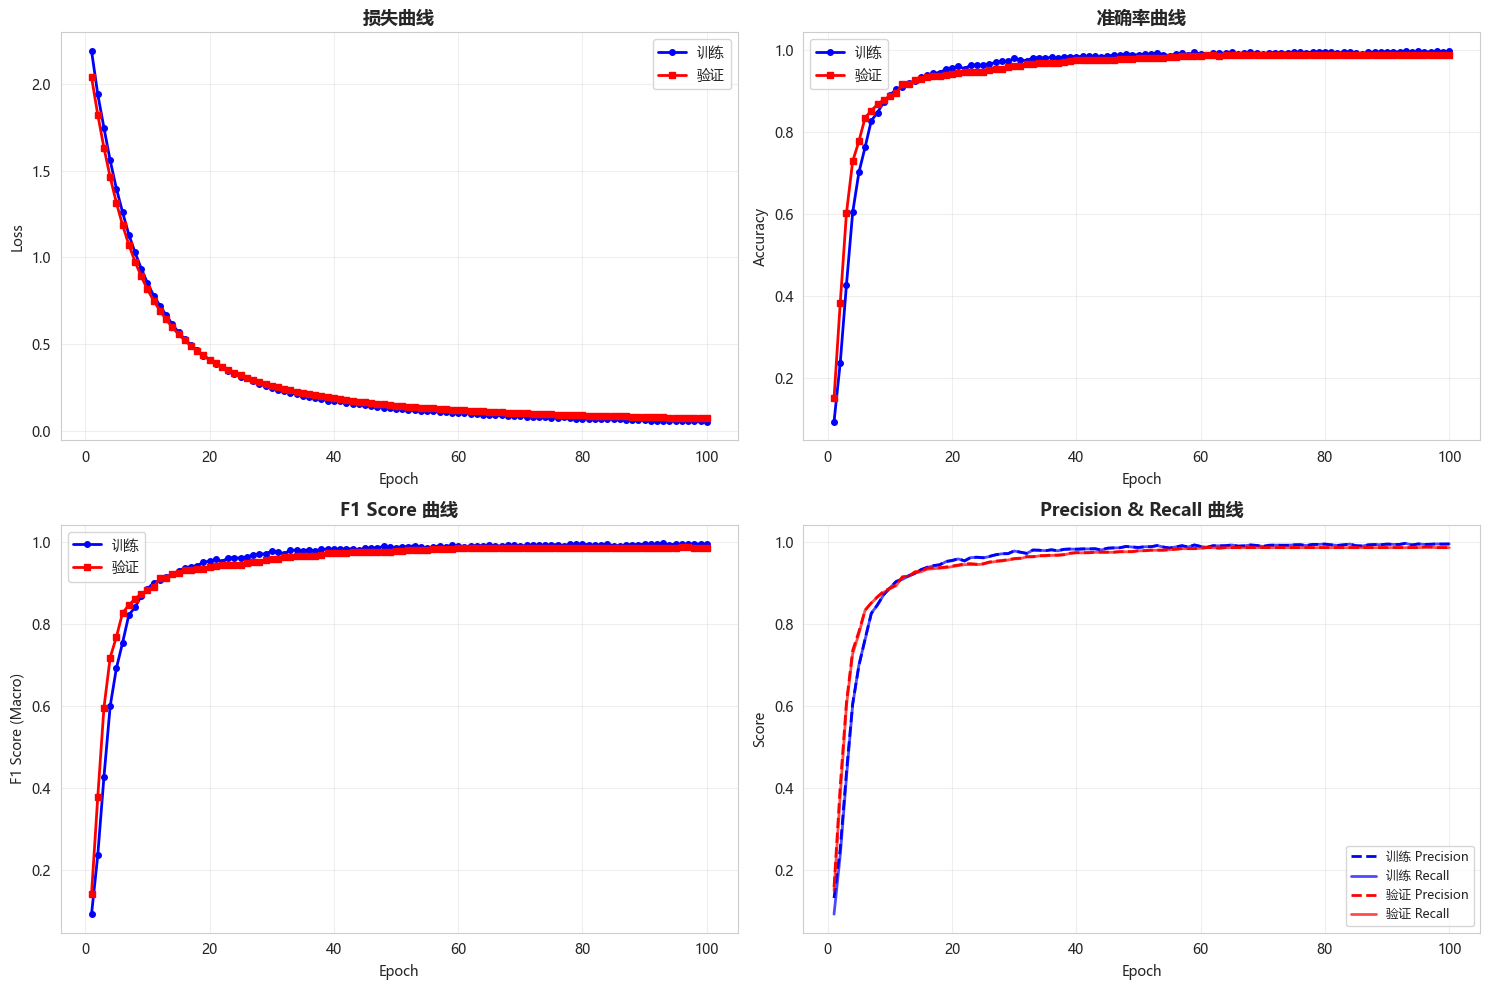

训练曲线已保存: D:\WorkSpace2\plants-intelligent-system\train\runs\mango_mdcn_training_curves.png


In [8]:
epochs = [h['epoch'] for h in history]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].plot(epochs, [h['train_loss'] for h in history], 'b-o', label='训练', linewidth=2, markersize=4)
axes[0, 0].plot(epochs, [h['val_loss'] for h in history], 'r-s', label='验证', linewidth=2, markersize=4)
axes[0, 0].set_title('损失曲线', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)

axes[0, 1].plot(epochs, [h['train_accuracy'] for h in history], 'b-o', label='训练', linewidth=2, markersize=4)
axes[0, 1].plot(epochs, [h['val_accuracy'] for h in history], 'r-s', label='验证', linewidth=2, markersize=4)
axes[0, 1].set_title('准确率曲线', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Accuracy')
axes[0, 1].legend()
axes[0, 1].grid(alpha=0.3)

axes[1, 0].plot(epochs, [h['train_f1_macro'] for h in history], 'b-o', label='训练', linewidth=2, markersize=4)
axes[1, 0].plot(epochs, [h['val_f1_macro'] for h in history], 'r-s', label='验证', linewidth=2, markersize=4)
axes[1, 0].set_title('F1 Score 曲线', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('F1 Score (Macro)')
axes[1, 0].legend()
axes[1, 0].grid(alpha=0.3)

axes[1, 1].plot(epochs, [h['train_precision'] for h in history], 'b--', label='训练 Precision', linewidth=2)
axes[1, 1].plot(epochs, [h['train_recall'] for h in history], 'b-', label='训练 Recall', linewidth=2, alpha=0.7)
axes[1, 1].plot(epochs, [h['val_precision'] for h in history], 'r--', label='验证 Precision', linewidth=2)
axes[1, 1].plot(epochs, [h['val_recall'] for h in history], 'r-', label='验证 Recall', linewidth=2, alpha=0.7)
axes[1, 1].set_title('Precision & Recall 曲线', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Score')
axes[1, 1].legend(fontsize=9)
axes[1, 1].grid(alpha=0.3)

plt.tight_layout()
curve_path = RUN_DIR / f'{MODEL_PREFIX}_training_curves.png'
plt.savefig(curve_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'训练曲线已保存: {curve_path}')

## 7. 测试集评估

In [9]:
print('\n开始测试集评估...')
model.eval()

y_true = []
y_pred = []
y_prob = []

with torch.inference_mode():
    for inputs, labels in tqdm(loaders['test'], desc='测试', leave=False, dynamic_ncols=True):
        inputs = inputs.to(DEVICE)
        outputs = model(inputs)
        probs = torch.softmax(outputs, dim=1)
        
        y_true.extend(labels.tolist())
        y_pred.extend(outputs.argmax(dim=1).cpu().tolist())
        y_prob.extend(probs.cpu().numpy())

y_prob = np.array(y_prob)

test_metrics = calculate_metrics(y_true, y_pred)
test_metrics['balanced_accuracy'] = float(balanced_accuracy_score(y_true, y_pred))

# Top-2 Accuracy
top2_correct = sum([label in np.argsort(prob)[-2:] for label, prob in zip(y_true, y_prob)])
test_metrics['top2_accuracy'] = float(top2_correct / len(y_true))

# ROC-AUC
y_true_binary = label_binarize(y_true, classes=list(range(num_classes)))
try:
    test_metrics['roc_auc_macro'] = float(roc_auc_score(y_true_binary, y_prob, multi_class='ovr', average='macro'))
    test_metrics['roc_auc_weighted'] = float(roc_auc_score(y_true_binary, y_prob, multi_class='ovr', average='weighted'))
except ValueError as e:
    print(f'警告: ROC-AUC 计算失败 - {e}')
    test_metrics['roc_auc_macro'] = None
    test_metrics['roc_auc_weighted'] = None

print('\n测试集结果:')
print(json.dumps(test_metrics, indent=2, ensure_ascii=False))

print('\n分类报告:')
print(classification_report(y_true, y_pred, target_names=class_names, digits=4, zero_division=0))

metrics_output = {
    'test_metrics': test_metrics,
    'best_epoch': best_epoch,
    'best_val_loss': best_val_loss,
    'class_to_idx': class_to_idx,
}
METRICS_PATH.write_text(json.dumps(metrics_output, indent=2, ensure_ascii=False), encoding='utf-8')
print(f'\n测试指标已保存: {METRICS_PATH}')

# 保存逐张预测，便于复查错误样本
with PREDICTIONS_PATH.open('w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(['file', 'true', 'pred', 'confidence'])
    for (path, _), t, p, prob in zip(image_datasets['test'].samples, y_true, y_pred, y_prob):
        writer.writerow([Path(path).name, class_names[t], class_names[p], f'{prob[p]:.6f}'])
print(f'预测明细已保存: {PREDICTIONS_PATH}')


开始测试集评估...



测试集结果:
{
  "accuracy": 0.9975,
  "precision": 0.9975490196078431,
  "recall": 0.9975,
  "f1_macro": 0.9974997499749976,
  "f1_weighted": 0.9974997499749975,
  "balanced_accuracy": 0.9975,
  "top2_accuracy": 1.0,
  "roc_auc_macro": 0.9999928571428571,
  "roc_auc_weighted": 0.9999928571428572
}

分类报告:
                  precision    recall  f1-score   support

     Anthracnose     1.0000    0.9800    0.9899        50
Bacterial Canker     1.0000    1.0000    1.0000        50
  Cutting Weevil     1.0000    1.0000    1.0000        50
        Die Back     1.0000    1.0000    1.0000        50
      Gall Midge     0.9804    1.0000    0.9901        50
         Healthy     1.0000    1.0000    1.0000        50
  Powdery Mildew     1.0000    1.0000    1.0000        50
     Sooty Mould     1.0000    1.0000    1.0000        50

        accuracy                         0.9975       400
       macro avg     0.9975    0.9975    0.9975       400
    weighted avg     0.9975    0.9975    0.9975       400


## 8. 混淆矩阵

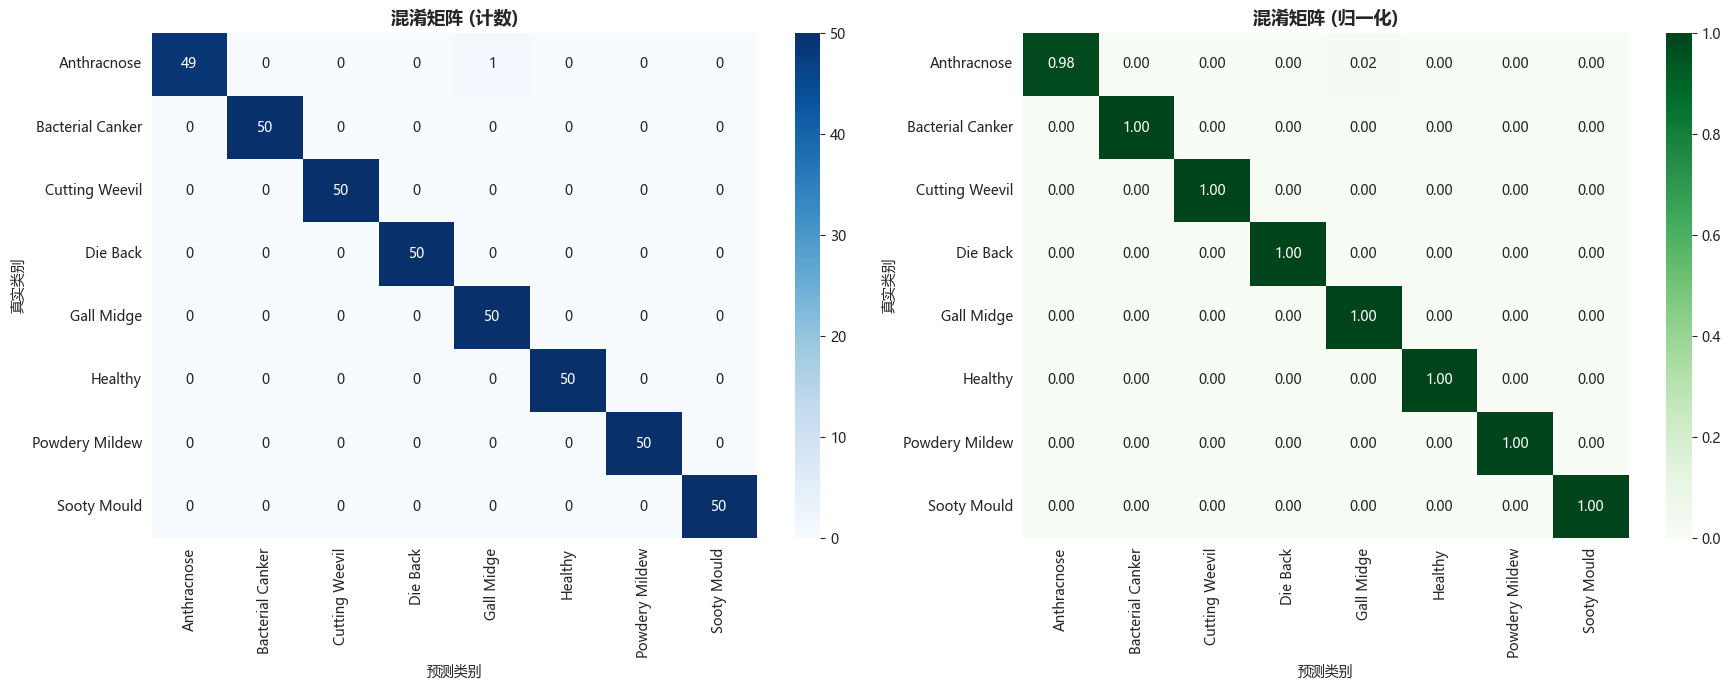

混淆矩阵已保存: D:\WorkSpace2\plants-intelligent-system\train\runs\mango_mdcn_confusion_matrix.png


In [10]:
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
cm_normalized = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('混淆矩阵 (计数)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('预测类别')
axes[0].set_ylabel('真实类别')

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('混淆矩阵 (归一化)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('预测类别')
axes[1].set_ylabel('真实类别')

plt.tight_layout()
cm_path = RUN_DIR / f'{MODEL_PREFIX}_confusion_matrix.png'
plt.savefig(cm_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'混淆矩阵已保存: {cm_path}')

## 9. ROC 曲线

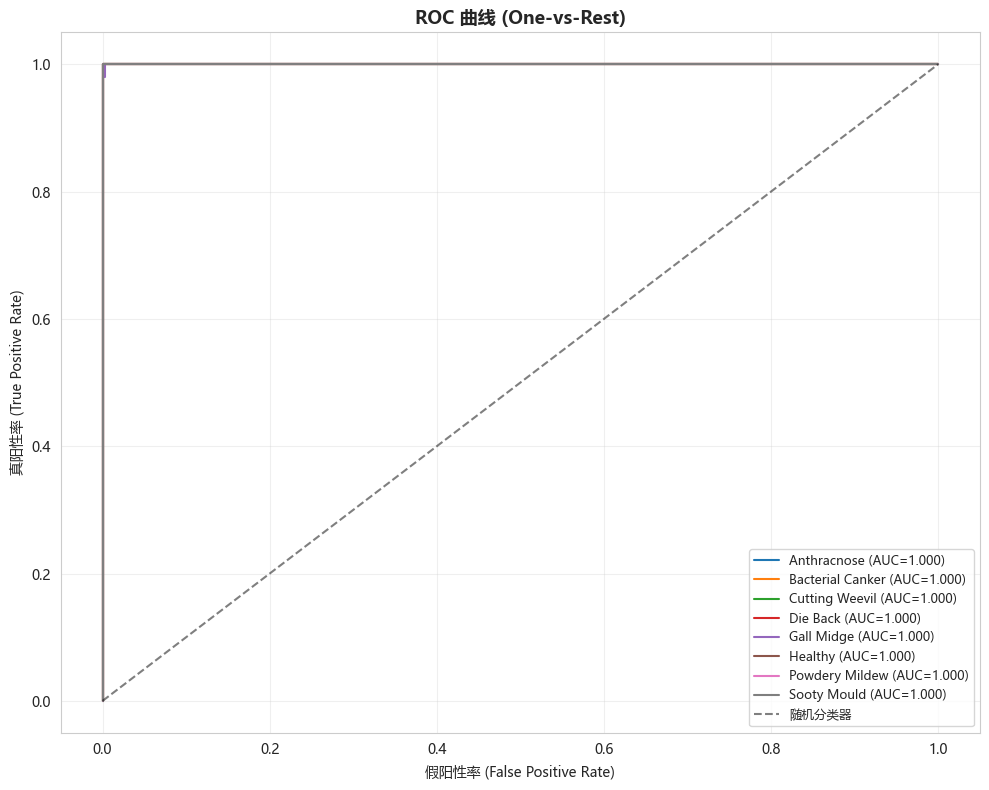

ROC 曲线已保存: D:\WorkSpace2\plants-intelligent-system\train\runs\mango_mdcn_roc_curve.png


In [11]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(10, 8))

for i, class_name in enumerate(class_names):
    try:
        fpr, tpr, _ = roc_curve(y_true_binary[:, i], y_prob[:, i])
        auc = roc_auc_score(y_true_binary[:, i], y_prob[:, i])
        plt.plot(fpr, tpr, label=f'{class_name} (AUC={auc:.3f})')
    except ValueError:
        pass

plt.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='随机分类器')
plt.xlabel('假阳性率 (False Positive Rate)')
plt.ylabel('真阳性率 (True Positive Rate)')
plt.title('ROC 曲线 (One-vs-Rest)', fontsize=13, fontweight='bold')
plt.legend(fontsize=9, loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()

roc_path = RUN_DIR / f'{MODEL_PREFIX}_roc_curve.png'
plt.savefig(roc_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'ROC 曲线已保存: {roc_path}')

## 10. 模型检查

In [12]:
print('\n验证模型加载...')
test_model = MDCN(num_classes=num_classes, dropout=DROPOUT_RATE, pretrained=False)
state = torch.load(FINAL_MODEL_PATH, map_location=DEVICE)
if isinstance(state, dict) and 'model_state_dict' in state:
    state = state['model_state_dict']
test_model.load_state_dict(state, strict=True)
test_model.to(DEVICE)
test_model.eval()

with torch.inference_mode():
    test_output = test_model(sample_batch.to(DEVICE))

assert test_output.shape == (sample_batch.shape[0], num_classes)
print('✓ 模型加载验证成功')
print(f'✓ 输出形状: {tuple(test_output.shape)}')
print('\n训练完成！所有文件已保存。')



验证模型加载...
✓ 模型加载验证成功
✓ 输出形状: (5, 8)

训练完成！所有文件已保存。


## 11. 跨设备评估（EXIF）

同一份数据由 4 台手机拍摄，类别与设备强相关。按拍摄设备拆分测试集，
看模型在不同设备上的表现差异——如果差异很大，说明模型可能学到了相机/背景线索。


设备                  样本    正确      准确率
M2004J19C           13    13   1.0000
RNE-L22            177   177   1.0000
SM-G935S           174   174   1.0000
vivo 1906           36    35   0.9722


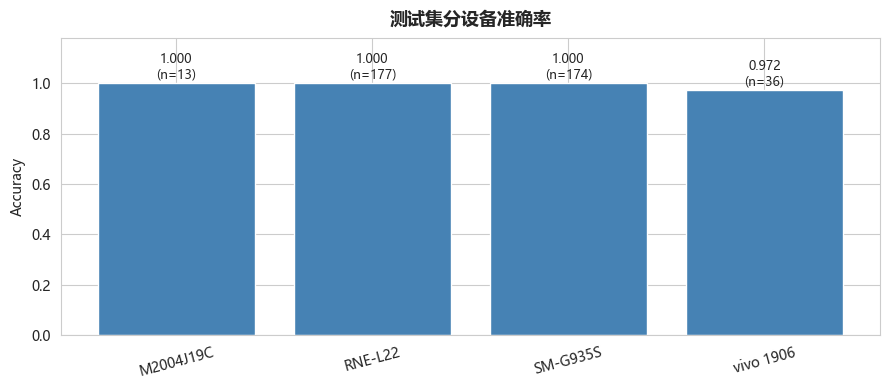

分设备准确率图已保存: D:\WorkSpace2\plants-intelligent-system\train\runs\mango_mdcn_device_accuracy.png


In [13]:
from PIL import Image

def exif_device(path):
    try:
        with Image.open(path) as im:
            model = im.getexif().get(272)
        return str(model).strip('\x00 ').strip() or 'unknown'
    except Exception:
        return 'unknown'

devices = [exif_device(p) for p, _ in image_datasets['test'].samples]
rows = []
for dev in sorted(set(devices)):
    idx = [i for i, d in enumerate(devices) if d == dev]
    ok = sum(1 for i in idx if y_true[i] == y_pred[i])
    rows.append((dev, len(idx), ok, ok / len(idx)))

print(f"{'设备':16s}{'样本':>6s}{'正确':>6s}{'准确率':>9s}")
for dev, n_dev, ok, acc in rows:
    print(f'{dev:16s}{n_dev:6d}{ok:6d}{acc:9.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar([r[0] for r in rows], [r[3] for r in rows], color='steelblue')
ax.set_ylim(0, 1.18)
ax.set_ylabel('Accuracy')
ax.set_title('测试集分设备准确率', fontsize=13, fontweight='bold', pad=10)
for i, r in enumerate(rows):
    ax.text(i, r[3] + 0.02, f'{r[3]:.3f}\n(n={r[1]})', ha='center', fontsize=9)
plt.xticks(rotation=15)
plt.tight_layout()
device_path = RUN_DIR / f'{MODEL_PREFIX}_device_accuracy.png'
plt.savefig(device_path, dpi=150, bbox_inches='tight')
plt.show()
print(f'分设备准确率图已保存: {device_path}')